# Workloads

- Workload traces are a recording of the tasks executed on a system 

- Graph Greenifier requires two different traces:
    - **tasks.parquet** provides a general overview of the tasks executed during the workload.
    - **fragments.parquet** provides detailed information of each task during its runtime 

In [1]:
import pandas as pd

df_tasks = pd.read_parquet("workload_traces/surf_month/tasks.parquet")
df_fragments = pd.read_parquet("workload_traces/surf_month/fragments.parquet")

## Workload Traces

- Traces define which tasks should be executed and when

- Provided as bag-of-task

- In this demo we run 1 month of Surfsara Lisa -> 68,648 tasks

In [2]:
df_tasks.head()

,id,submission_time,duration,cpu_count,cpu_capacity,mem_capacity,deferrable,deadline
0,1519830,1656604920000,1000,16,33600.0,97,True,1656691320000
1,1519833,1656604949000,1000,16,33600.0,97,True,1656691349000
2,1520988,1656605328000,315000,16,33600.0,97,True,1656691728000
3,1520994,1656605793000,330000,16,33600.0,97,True,1656692193000
4,1521049,1656608110000,248000,16,33600.0,97,True,1656694510000


### Fragments

<img src="./figures/fragments.jpg" width=600, alt="Alternative text" />

##### One month of Surfsara tasks has over 10 million fragments

In [3]:
df_fragments.head()

,id,duration,cpu_usage
0,1519830,1000,33600.0
1,1519833,1000,33600.0
2,1520988,12000,0.0
3,1520988,30000,420.0
4,1520988,30000,966.0


# Carbon Trace

Carbon Traces define the Carbon Intenisty of the available energy over time

Gathered using ENTSO-E

Specific to the location of the data center

Defined as a parquet file

In [4]:
df_carbon = pd.read_parquet("carbon_traces/NL_2021-2024.parquet")

df_carbon.head()

,timestamp,carbon_intensity
0,2021-01-01 00:00:00,464.62
1,2021-01-01 01:00:00,459.98
2,2021-01-01 02:00:00,454.93
3,2021-01-01 03:00:00,448.39
4,2021-01-01 04:00:00,455.50


# Experiment

- An Experiment defines what the Graph Greenifier should run, and how.

- Eperiments are defined using a JSON format

See the Experiment file [here](experiments/surfsara_month.json)

**Note:** Parameters are defined as lists, this makes it easy to run multiple experiments

# Running OpenDC

- OpenDC is executed directly from the terminal

- Only an experiment file is needed

In [6]:
import subprocess

pathToExperiment = "experiments/5.temporal_shifting/shifting_experiment.json"
result = subprocess.run(["OpenDCExperimentRunner/bin/opendc", "run", pathToExperiment])

Starting replay


WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 139
						Tasks Pending: 64
						Tasks Completed: 969
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 139
						Tasks Pending: 64
						Tasks Completed: 969
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 139
						Tasks Pending: 64
						Tasks Completed: 969
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 30
						Tasks Pending: 0
						Tasks Completed: 1383
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 30
						Tasks Pending: 0
						Tasks Completed: 1383
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 30
						Tasks Pending: 0
						Tasks Completed: 1383
						Tasks Terminated: 0

WARN  
					Metrics after 72 ho

Starting replay


WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 136
						Tasks Pending: 0
						Tasks Completed: 1036
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 136
						Tasks Pending: 0
						Tasks Completed: 1036
						Tasks Terminated: 0

WARN  
					Metrics after 24 hours:
						Tasks Total: 1172
						Tasks Active: 136
						Tasks Pending: 0
						Tasks Completed: 1036
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 29
						Tasks Pending: 0
						Tasks Completed: 1384
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 29
						Tasks Pending: 0
						Tasks Completed: 1384
						Tasks Terminated: 0

WARN  
					Metrics after 48 hours:
						Tasks Total: 1413
						Tasks Active: 29
						Tasks Pending: 0
						Tasks Completed: 1384
						Tasks Terminated: 0

WARN  
					Metrics after 72 ho

┌─────────┬──────┬──────┬──────────┬──────────┬────────┬───────────┬──────────┐
│ Scenario│ Seed │ Tasks│ Completed│ Terminate│ Mean CP│ Energy [kW│ Carbon [k│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #0      │ 0    │ 47117│ 47117    │ 0        │ 18.8%  │ 4612293.35│ 1573769.6│
├─────────┼──────┼──────┼──────────┼──────────┼────────┼───────────┼──────────┤
│ #1      │ 0    │ 47117│ 47117    │ 0        │ 18.9%  │ 4677724.50│ 1541216.8│
└─────────┴──────┴──────┴──────────┴──────────┴────────┴───────────┴──────────┘
Simulated 2 run(s); Parquet results in output


## 6. Output

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df_host_base = pd.read_parquet("output/5.temporal_shifting/raw-output/0/seed=0/host.parquet")
df_powerSource_base = pd.read_parquet("output/5.temporal_shifting/raw-output/0/seed=0/powerSource.parquet")
df_task_base = pd.read_parquet("output/5.temporal_shifting/raw-output/0/seed=0/task.parquet")
df_service_base = pd.read_parquet("output/5.temporal_shifting/raw-output/0/seed=0/service.parquet")

df_host_shifted = pd.read_parquet("output/5.temporal_shifting/raw-output/1/seed=0/host.parquet")
df_powerSource_shifted = pd.read_parquet("output/5.temporal_shifting/raw-output/1/seed=0/powerSource.parquet")
df_task_shifted = pd.read_parquet("output/5.temporal_shifting/raw-output/1/seed=0/task.parquet")
df_service_shifted = pd.read_parquet("output/5.temporal_shifting/raw-output/1/seed=0/service.parquet")


# Vizualization

The results of our experiment can be used to visualize the effect of Carbon-Aware scheduling.
We show the effect on when tasks are scheduled and how this effects the energy usage and carbon emissions. 

### Active Tasks

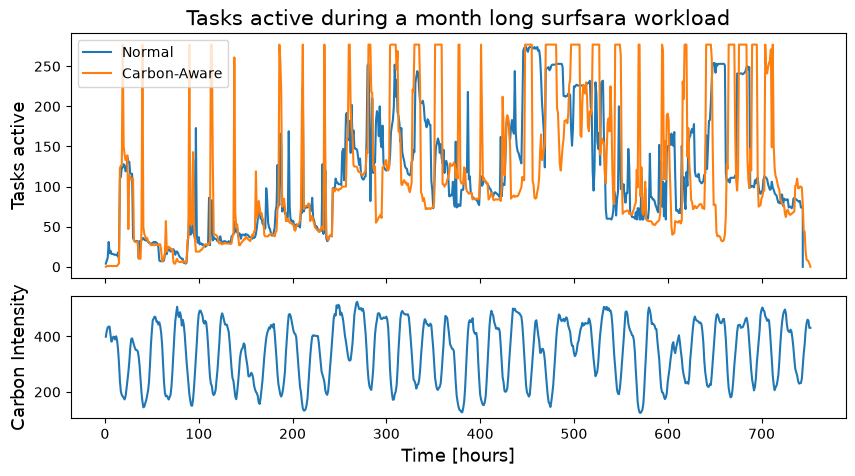

In [ ]:
import matplotlib.dates as mdates

fig, (ax0, ax1) = plt.subplots(2,1, height_ratios = [2,1], figsize=(10,5), sharex=True, gridspec_kw={'hspace': 0.1})
ax0.plot(df_service_base.timestamp / 3_600_000, df_service_base.tasks_active, label="Normal")
ax0.plot(df_service_shifted.timestamp / 3_600_000, df_service_shifted.tasks_active, label="Carbon-Aware")

ax0.legend(loc="upper left", fontsize=10)

ax0.set_title("Tasks active during a month long surfsara workload", fontsize=15)
ax0.set_ylabel("Tasks active", fontsize=13)
ax0.xaxis.set_major_locator(plt.MaxNLocator(10))

ax1.plot(df_service_shifted.timestamp / 3_600_000, df_powerSource_shifted.carbon_intensity, label="Shifted")

ax1.set_xlabel("Time [hours]", fontsize=13)
ax1.set_ylabel("Carbon Intensity", fontsize=13)

plt.show()

### Energy Usage

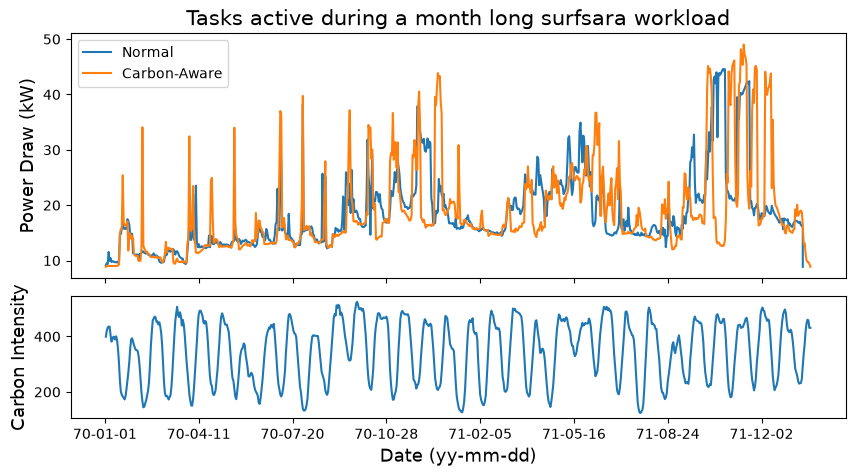

In [ ]:
import matplotlib.dates as mdates

fig, (ax0, ax1) = plt.subplots(2,1, height_ratios = [2,1], figsize=(10,5), sharex=True, gridspec_kw={'hspace': 0.1})
ax0.plot(df_powerSource_base.timestamp / 3_600_000, df_powerSource_base.power_draw / 1000, label="Normal")
ax0.plot(df_powerSource_shifted.timestamp / 3_600_000, df_powerSource_shifted.power_draw / 1000, label="Carbon-Aware")

ax0.legend(loc="upper left", fontsize=10)

ax0.set_title("Tasks active during a month long surfsara workload", fontsize=15)
ax0.set_ylabel("Power Draw (kW)", fontsize=13)
ax0.xaxis.set_major_locator(plt.MaxNLocator(10))

ax1.plot(df_powerSource_shifted.timestamp / 3_600_000, df_powerSource_shifted.carbon_intensity, label="Shifted")

myFmt = mdates.DateFormatter('%y-%m-%d')
ax1.xaxis.set_major_formatter(myFmt)
ax1.set_xlabel("Time [hours]", fontsize=13)
ax1.set_ylabel("Carbon Intensity", fontsize=13)

plt.show()

### Carbon Emission

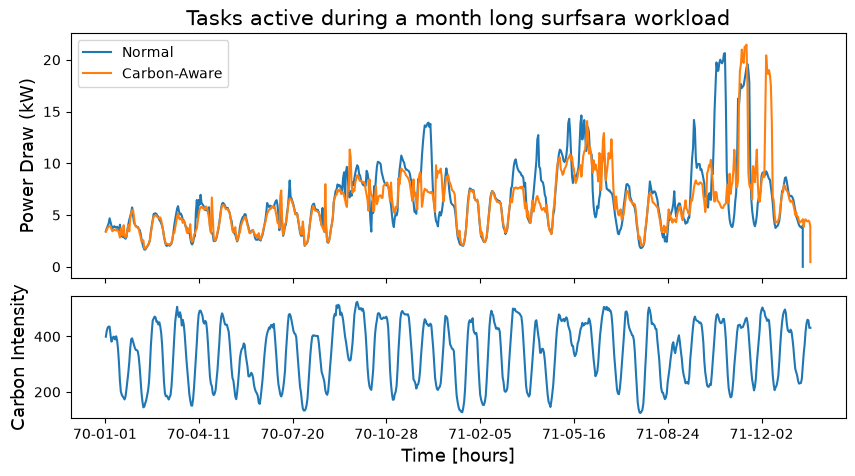

In [28]:
import matplotlib.dates as mdates

df_powerSource_base["carbon_diff"] = df_powerSource_base.carbon_emission - df_powerSource_base.carbon_emission.shift(1, fill_value=0)
df_powerSource_shifted["carbon_diff"] = df_powerSource_shifted.carbon_emission - df_powerSource_shifted.carbon_emission.shift(1, fill_value=0)

fig, (ax0, ax1) = plt.subplots(2,1, height_ratios = [2,1], figsize=(10,5), sharex=True, gridspec_kw={'hspace': 0.1})
ax0.plot(df_powerSource_base.timestamp / 3_600_000, df_powerSource_base.carbon_diff / 1000, label="Normal")
ax0.plot(df_powerSource_shifted.timestamp / 3_600_000, df_powerSource_shifted.carbon_diff / 1000, label="Carbon-Aware")

ax0.legend(loc="upper left", fontsize=10)

ax0.set_title("Tasks active during a month long surfsara workload", fontsize=15)
ax0.set_ylabel("Power Draw (kW)", fontsize=13)
ax0.xaxis.set_major_locator(plt.MaxNLocator(10))

ax1.plot(df_powerSource_shifted.timestamp / 3_600_000, df_powerSource_shifted.carbon_intensity, label="Shifted")

myFmt = mdates.DateFormatter('%y-%m-%d')
ax1.xaxis.set_major_formatter(myFmt)
ax1.set_xlabel("Time [hours]", fontsize=13)
ax1.set_ylabel("Carbon Intensity", fontsize=13)

plt.show()

In [27]:
df_powerSource_base.head()

,timestamp,power_source_id,power_draw,energy_usage,carbon_intensity,carbon_emission,carbon_diff
0,3600000,0,9136.618164,32410218.0,399.190002,3437.621338,399.190002
1,7200000,0,9517.060547,65945888.0,420.549988,7163.004883,21.359985
2,10800000,0,9397.452148,99825520.0,432.170013,11124.446289,11.620026
3,14400000,0,11552.772461,134720080.0,435.730011,15314.796875,3.559998
4,18000000,0,9913.951172,173452448.0,435.250000,20002.652344,-0.480011


# Aggregated Results

In [29]:
energy = df_powerSource_base.energy_usage.max() / 3_600_000 # convert energy to kWh
energy_shifted = df_powerSource_shifted.energy_usage.max() / 3_600_000 # convert energy to kWh

carbon = df_powerSource_base.carbon_emission.max() / 1000
carbon_shifted = df_powerSource_shifted.carbon_emission.max() / 1000

print(f"Normal scheduling used {energy:.2f} kWh during the workload")
print(f"Carbon-aware scheduling used {energy_shifted:.2f} kWh during the workload\n\n")

print(f"Normal scheduling emitted {carbon:.2f} kg CO2 during the workload")
print(f"Carbon-aware scheduling emitted {carbon_shifted:.2f} kg CO2 during the workload")
print(f"This is a decrease of {((carbon - carbon_shifted) / carbon) * 100:.2f}%\n\n")

Normal scheduling used 13837.17 kWh during the workload
Carbon-aware scheduling used 13910.85 kWh during the workload


Normal scheduling emitted 4856.71 kg CO2 during the workload
Carbon-aware scheduling emitted 4687.94 kg CO2 during the workload
This is a decrease of 3.47%


